1. Exploratory Data Analysis (EDA):     
Perform exploratory data analysis to understand the structure of the dataset.       
Check for missing values, outliers, inconsistencies in the data.


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
df=pd.read_excel('glass.xlsx',sheet_name='glass')

In [40]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [41]:
df.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [42]:
df.duplicated().sum()

np.int64(1)

In [43]:
df.drop_duplicates(inplace=True)

In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
df.info()

<class 'pandas.DataFrame'>
Index: 213 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      213 non-null    float64
 1   Na      213 non-null    float64
 2   Mg      213 non-null    float64
 3   Al      213 non-null    float64
 4   Si      213 non-null    float64
 5   K       213 non-null    float64
 6   Ca      213 non-null    float64
 7   Ba      213 non-null    float64
 8   Fe      213 non-null    float64
 9   Type    213 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 18.3 KB


In [46]:
df.shape

(213, 10)

In [47]:
features=df.drop(columns=['Type'])
target=df['Type']

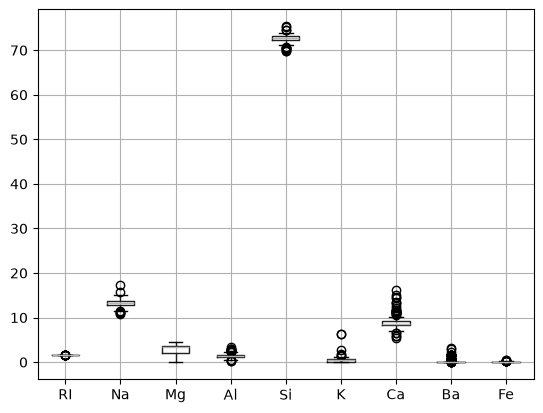

In [48]:
features.boxplot()
plt.show()

In [49]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

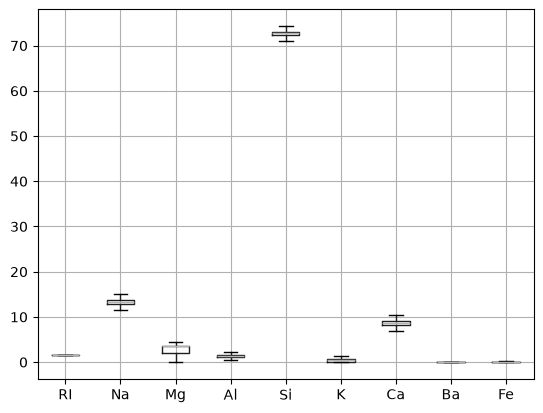

In [50]:
features.boxplot()
plt.show()

2: Data Visualization:      
Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.
Analyze any patterns or correlations observed in the data.


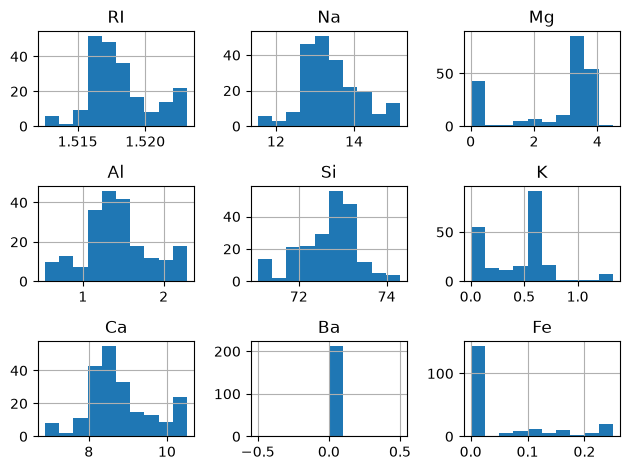

In [51]:
features.hist()
plt.tight_layout()
plt.show()

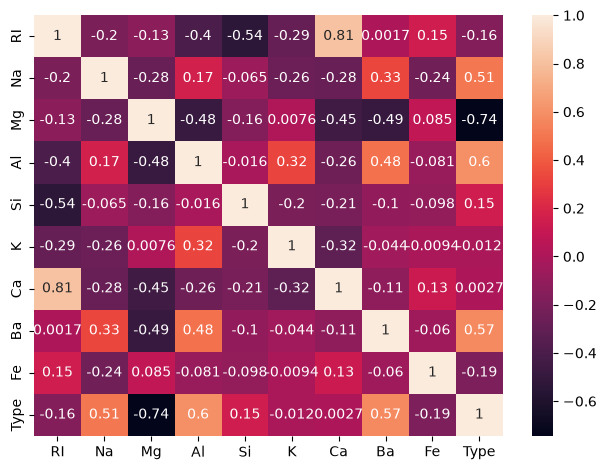

In [52]:
cor=df.corr()
sns.heatmap(cor,annot=True)
plt.tight_layout()
plt.show()

In [53]:
from sklearn.feature_selection import f_classif

In [54]:
f_cls=f_classif(features,target)
pd.DataFrame(f_cls[0],index=features.columns)

C:\Users\pprem\AppData\Roaming\Python\Python314\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [7] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\pprem\AppData\Roaming\Python\Python314\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,0
RI,2.042620
Na,31.490390
Mg,64.962626
Al,35.631814
Si,2.845113
K,10.764863
Ca,3.393418
Ba,NaN
Fe,3.178148


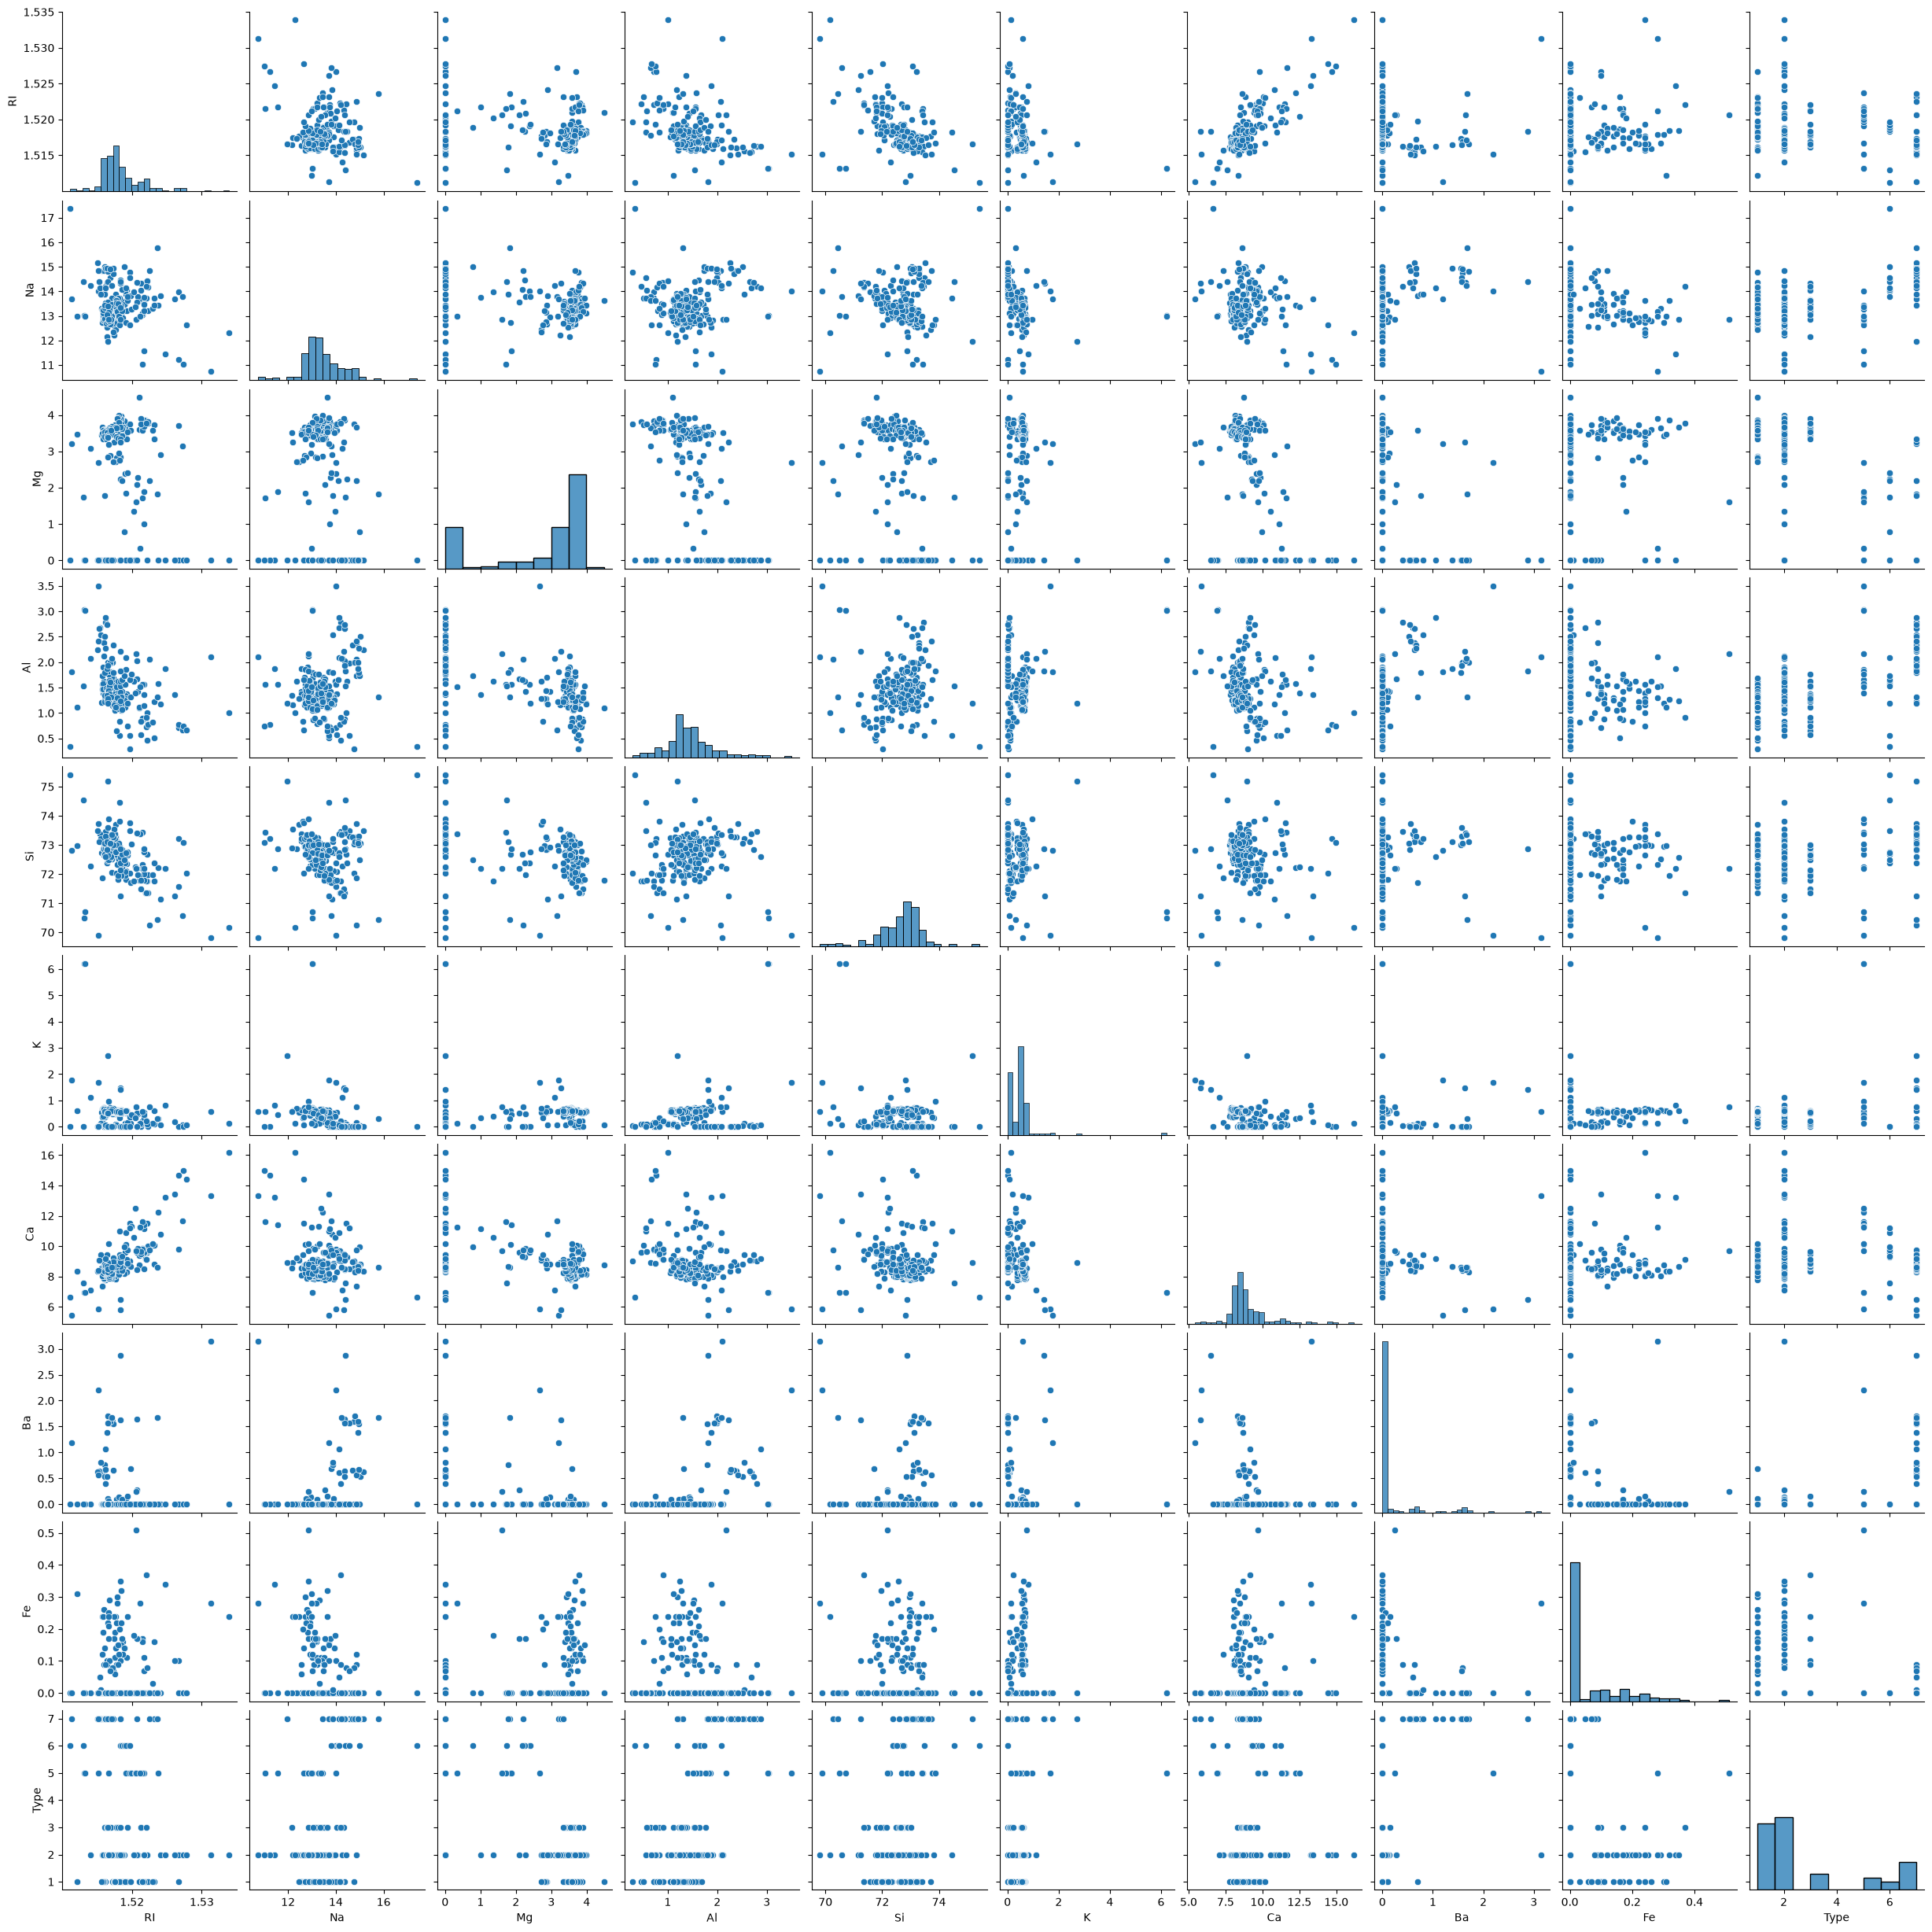

In [55]:
sns.pairplot(df)
plt.show()

3: Data Preprocessing       

1. Check for missing values in the dataset and decide on a strategy for handling them.Implement the chosen strategy (e.g., imputation or removal) and explain your reasoning.       
2. If there are categorical variables, apply encoding techniques like one-hot encoding to convert them into numerical format.       
3. Apply feature scaling techniques such as standardization or normalization to ensure that all features are on a similar scale. Handling the imbalance data.


In [56]:
from sklearn.preprocessing import StandardScaler

In [57]:
std_sca=StandardScaler()

In [58]:
features=std_sca.fit_transform(features)

4: Random Forest Model Implementation       
1. Divide the data into train and test split.       
2. Implement a Random Forest classifier using Python and a machine learning library like scikit-learn.      
3. Train the model on the train dataset. Evaluate the performance on test data using metrics like accuracy, precision, recall, and F1-score.


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [63]:
x_train,x_test,y_train,y_test=train_test_split(features,target,test_size=0.2,random_state=42)

In [65]:
rf_model=RandomForestClassifier()

In [66]:
rf_model.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [67]:
y_pred=rf_model.predict(x_test)

In [68]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           1       0.77      1.00      0.87        10
           2       0.80      0.80      0.80        15
           3       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         3
           6       1.00      0.67      0.80         3
           7       1.00      0.78      0.88         9

    accuracy                           0.86        43
   macro avg       0.93      0.87      0.89        43
weighted avg       0.88      0.86      0.86        43




5: Bagging and Boosting Methods     
Apply the Bagging and Boosting methods and compare the results.


In [70]:
from sklearn.ensemble import BaggingClassifier,GradientBoostingClassifier

In [74]:
bc=BaggingClassifier(estimator=RandomForestClassifier(random_state=100))

In [75]:
bc.fit(x_train,y_train)
y_pred=bc.predict(x_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           1       0.69      0.90      0.78        10
           2       0.75      0.80      0.77        15
           3       1.00      0.67      0.80         3
           5       1.00      1.00      1.00         3
           6       1.00      0.67      0.80         3
           7       1.00      0.78      0.88         9

    accuracy                           0.81        43
   macro avg       0.91      0.80      0.84        43
weighted avg       0.84      0.81      0.82        43



In [76]:
gbc=GradientBoostingClassifier()

In [77]:
gbc.fit(x_train,y_train)
y_pred=gbc.predict(x_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           1       0.75      0.90      0.82        10
           2       0.80      0.80      0.80        15
           3       0.50      0.33      0.40         3
           5       0.60      1.00      0.75         3
           6       1.00      0.67      0.80         3
           7       1.00      0.78      0.88         9

    accuracy                           0.79        43
   macro avg       0.78      0.75      0.74        43
weighted avg       0.81      0.79      0.79        43



Additional Notes:       
1. Explain Bagging and Boosting methods. How is it different from each other.



In [80]:
print("""

Bagging builds multiple independent models in parallel and averages their predictions to get a final result. 
It acts like a majority vote among experts to reduce variance and prevent the model from overfitting.
Boosting builds models sequentially, where each new model specifically focuses on correcting 
the mistakes made by the previous one. This iterative approach reduces bias and drives up the model's overall accuracy.
Bagging runs in parallel to prevent overfitting, while Boosting runs sequentially to continuously learn from past mistakes.

""")



Bagging builds multiple independent models in parallel and averages their predictions to get a final result. 
It acts like a majority vote among experts to reduce variance and prevent the model from overfitting.
Boosting builds models sequentially, where each new model specifically focuses on correcting 
the mistakes made by the previous one. This iterative approach reduces bias and drives up the model's overall accuracy.
Bagging runs in parallel to prevent overfitting, while Boosting runs sequentially to continuously learn from past mistakes.




2. Explain how to handle imbalance in the data.

In [79]:
print(""" 

You can handle imbalance at the data level by artificially generating more samples for the 
rare class (oversampling/SMOTE). Alternatively, you can handle it at the algorithm level by 
applying class weights, which heavily penalizes the model for misclassifying the minority class.

""")

 

You can handle imbalance at the data level by artificially generating more samples for the 
rare class (oversampling/SMOTE). Alternatively, you can handle it at the algorithm level by 
applying class weights, which heavily penalizes the model for misclassifying the minority class.


